# Synthetic Data Generation using TabFairGAN

This notebook implements a TabFairGAN (Tabular Fair GAN) model to generate synthetic data.

The objective is to compare TabFairGAN with non-fair models in terms of:
- Data quality
- Preservation of statistical properties
- Fairness across sensitive attributes

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tabfairgan import TFG

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

/Users/staceykagio/fair-synthetic-data-gen/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

We use the Adult Income dataset which is our test data.

In [2]:
df = pd.read_csv("test_data/adult.csv")

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Data Preprocessing

We define categorical variables and clean the dataset.

In [3]:
df = df.dropna()

categorical_columns = [
    'workclass', 'education', 'marital-status',
    'occupation', 'relationship', 'race',
    'sex', 'native-country', 'income'
]

## TabFairGAN Model Training

TabFairGAN differs from standard generative models such as CTGAN in that fairness constraints are incorporated directly into the training process.

Instead of using a separate fit function, the model is trained using a custom training loop.

### Fairness Constraint
To generate fair synthetic data, you need to pass a dictionary containing the following parameters:

- fair_epochs: Number of fair training epochs (integer).
- lamda: Lambda parameter controlling the trade-off between fairness and accuracy (float).
- S: Protected attribute (string, e.g., "sex").
- Y: Decision label (string, e.g., "income").
- S_under: Value representing the underprivileged group for the protected attribute (string, e.g., " Female").
- Y_desire: Desired value for the label (string, e.g., " >50K").

In [4]:
# Define fairness configuration
fairness_config = {
    'fair_epochs': 50,
    'lamda': 0.5,
    'S': 'sex',
    'Y': 'income',
    'S_under': 'Female',
    'Y_desire': '>50K'
}

# Initialize TabFairGAN with fairness constraints
model = TFG(
    df, 
    epochs=200, 
    batch_size=256, 
    fairness_config=fairness_config
)

# Train the model
model.train()

Training Progress:   0%|                             | 0/200 [00:00<?, ?it/s, Training for accuracy]

epoch 1


Training Progress:   0%|                     | 1/200 [00:07<25:41,  7.75s/it, Training for accuracy]

epoch 2


Training Progress:   1%|▏                    | 2/200 [00:15<24:56,  7.56s/it, Training for accuracy]

...

Training Progress:  99%|██████████████████▊| 198/200 [39:40<00:22, 11.19s/it, Training for fairness]

epoch 199


Training Progress: 100%|██████████████████▉| 199/200 [39:51<00:11, 11.16s/it, Training for fairness]

epoch 200


Training Progress: 100%|███████████████████| 200/200 [40:04<00:00, 12.02s/it, Training for fairness]


## Synthetic Data Generation

In [5]:
tabfairgan_synthetic_data = model.generate_fake_df(num_rows=5000)

tabfairgan_synthetic_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,50.0,Federal-gov,60048.015625,HS-grad,9.0,Divorced,Adm-clerical,Unmarried,White,Female,0.0,0.0,40.0,United-States,<=50K
1,46.0,Local-gov,165304.296875,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,40.0,United-States,>50K
2,43.0,Private,166253.828125,HS-grad,9.0,Married-civ-spouse,Craft-repair,Husband,White,Male,0.0,0.0,40.0,United-States,>50K
3,35.0,Private,13769.000000,11th,7.0,Separated,Sales,Own-child,White,Female,0.0,0.0,1.0,United-States,<=50K
4,33.0,Private,162528.296875,Bachelors,15.0,Never-married,Prof-specialty,Not-in-family,White,Female,0.0,0.0,45.0,United-States,<=50K


Export the synthetic data for analysis

In [6]:
tabfairgan_synthetic_data.to_csv("tabfairgan_synthetic.csv", index=False)

## Distribution Comparison

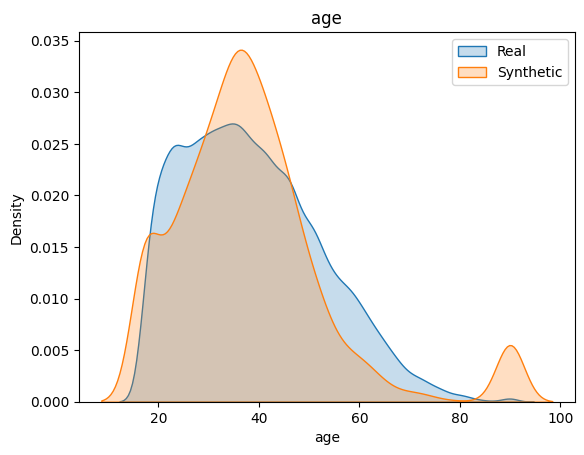

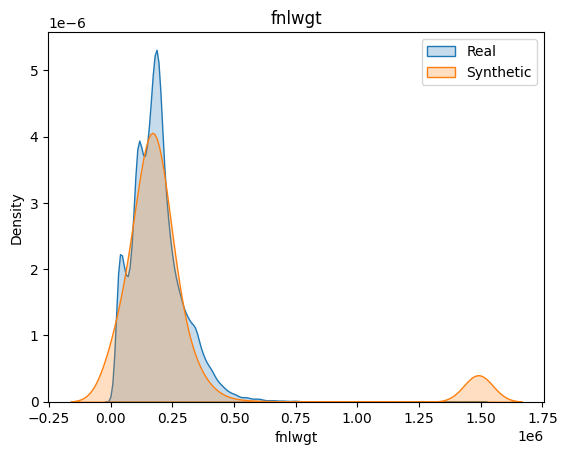

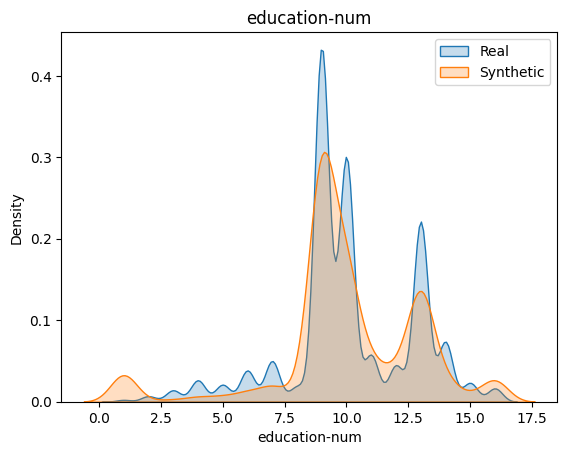

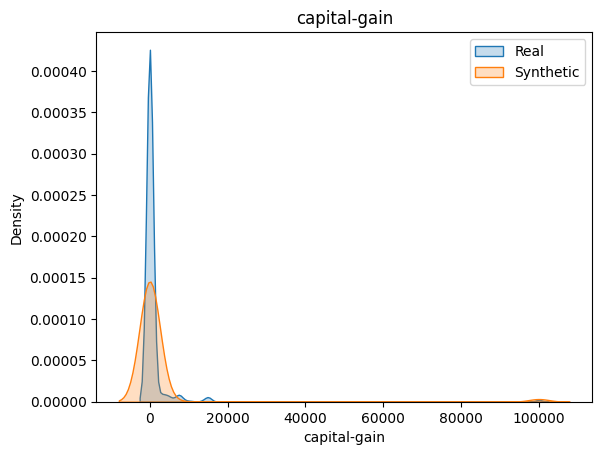

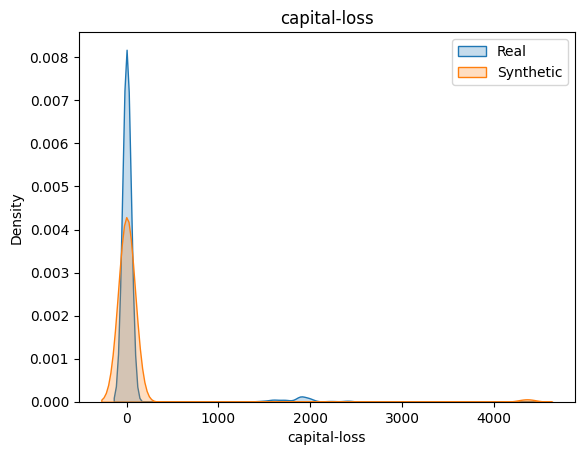

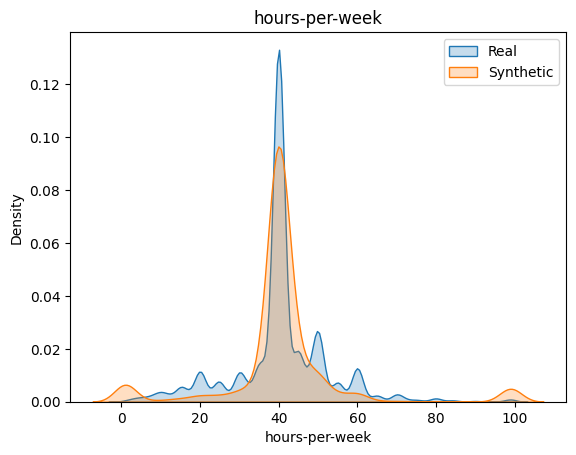

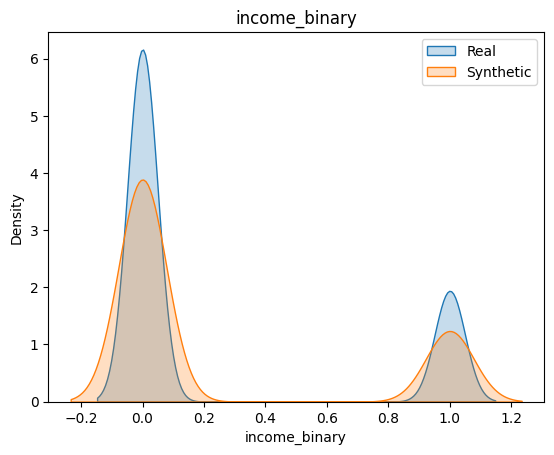

In [12]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    plt.figure()
    sns.kdeplot(df[col], label="Real", fill=True)
    sns.kdeplot(tabfairgan_synthetic_data[col], label="Synthetic", fill=True)
    plt.title(col)
    plt.legend()
    plt.show()

## Fairness Evaluation

In [13]:
#Convert income to binary
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
tabfairgan_synthetic_data['income_binary'] = tabfairgan_synthetic_data['income'].apply(lambda x: 1 if '>50K' in x else 0)

In [14]:
#Statistical Parity
real_sp = df.groupby('sex')['income_binary'].mean()
syn_sp = tabfairgan_synthetic_data.groupby('sex')['income_binary'].mean()

print("Real:")
print(real_sp)

print("\nSynthetic:")
print(syn_sp)

Real:
sex
Female    0.109251
Male      0.303767
Name: income_binary, dtype: float64

Synthetic:
sex
Female    0.026299
Male      0.342051
Name: income_binary, dtype: float64


In [15]:
#Disparity Gap
real_sp = df.groupby('sex')['income_binary'].mean()
syn_sp = tabfairgan_synthetic_data.groupby('sex')['income_binary'].mean()

print("Real:")
print(real_sp)

print("\nSynthetic:")
print(syn_sp)

Real:
sex
Female    0.109251
Male      0.303767
Name: income_binary, dtype: float64

Synthetic:
sex
Female    0.026299
Male      0.342051
Name: income_binary, dtype: float64


## Downstream Classifier
To evaluate the utility of the generated data, standard machine learning classifiers will be trained using the synthetic datasets.

### Logistic Regression


#### Data Preprocessing

In [16]:
# CLEAN DATA 
def clean_dataframe(df):
    df = df.copy()
    
    # Remove leading/trailing spaces in strings
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()
    
    return df


# Clean datasets
real_train_df = clean_dataframe(df)
synthetic_df = clean_dataframe(tabfairgan_synthetic_data)


real_train_df, real_test_df = train_test_split(real_train_df, test_size=0.2, random_state=42)

def encode_target(df, target_col):
    df = df.copy()
    df[target_col] = df[target_col].astype(str)
    df[target_col] = df[target_col].str.strip()
    df[target_col] = df[target_col].str.replace(".", "", regex=False)
    df[target_col] = df[target_col].map({
        "<=50K": 0,
        ">50K": 1
    })
    return df

real_train_df = encode_target(real_train_df, "income")
real_test_df = encode_target(real_test_df, "income")
synthetic_df = encode_target(synthetic_df, "income")


#  BUILD PIPELINE
def build_pipeline(df, target_col):
    X = df.drop(columns=[target_col])
    
    categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
    numerical_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
            ("num", "passthrough", numerical_cols)
        ]
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ])
    
    return pipeline


# FAIRNESS METRICS
def demographic_parity(y_pred, sensitive):
    groups = sensitive.unique()
    rates = [y_pred[sensitive == g].mean() for g in groups]
    return abs(rates[0] - rates[1])


def disparate_impact(y_pred, sensitive):
    groups = sensitive.unique()
    rate_0 = y_pred[sensitive == groups[0]].mean()
    rate_1 = y_pred[sensitive == groups[1]].mean()
    return min(rate_0 / (rate_1 + 1e-6), rate_1 / (rate_0 + 1e-6))


def equal_opportunity(y_true, y_pred, sensitive):
    groups = sensitive.unique()
    tprs = []
    
    for g in groups:
        mask = (sensitive == g)
        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        tprs.append(tp / (tp + fn + 1e-6))
    
    return abs(tprs[0] - tprs[1])


def equalized_odds(y_true, y_pred, sensitive):
    groups = sensitive.unique()
    tpr_list, fpr_list = [], []
    
    for g in groups:
        mask = (sensitive == g)
        
        tp = ((y_pred == 1) & (y_true == 1) & mask).sum()
        fn = ((y_pred == 0) & (y_true == 1) & mask).sum()
        fp = ((y_pred == 1) & (y_true == 0) & mask).sum()
        tn = ((y_pred == 0) & (y_true == 0) & mask).sum()
        
        tpr = tp / (tp + fn + 1e-6)
        fpr = fp / (fp + tn + 1e-6)
        
        tpr_list.append(tpr)
        fpr_list.append(fpr)
    
    return abs(tpr_list[0] - tpr_list[1]) + abs(fpr_list[0] - fpr_list[1])


# TRAIN + EVALUATE
def run_tabfairgan_evaluation(train_df, test_df, target_col, sensitive_col):
    
    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]

    X_test = test_df.drop(columns=[target_col])
    y_test = test_df[target_col]
    sensitive = test_df[sensitive_col]

    model = build_pipeline(train_df, target_col)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results = {
        "accuracy": accuracy_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "demographic_parity": demographic_parity(y_pred, sensitive),
        "disparate_impact": disparate_impact(y_pred, sensitive),
        "equal_opportunity": equal_opportunity(y_test, y_pred, sensitive),
        "equalized_odds": equalized_odds(y_test, y_pred, sensitive)
    }

    return results


# RUN IT
results = run_tabfairgan_evaluation(
    train_df=synthetic_df,        # train on synthetic
    test_df=real_test_df,         # test on real
    target_col="income",
    sensitive_col="sex"
)

print("TabFairGAN Results:")
print(results)

TabFairGAN Results:
{'accuracy': 0.9971337905619818, 'f1': 0.9940222032450897, 'demographic_parity': 0.19961139352023444, 'disparate_impact': 0.3443907944791533, 'equal_opportunity': 0.07073036619182205, 'equalized_odds': 0.07095033979494128}


/Users/staceykagio/fair-synthetic-data-gen/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Random Forest